# Summary

This is a notebook contains an example of a vision model from fastai that classifies pictures as cats or dogs. It uses a pretrained model as base and fine tune it with images of dogs and cats from [The Oxford-IIIT Pet Dataset ](https://www.robots.ox.ac.uk/~vgg/data/pets/).

In order to do the training we will:

1. Install the appropiate depenencies.
2. Create the appropiate data loader.
3. Create a learner & Fine tune
4. Use the fine tuned model to make predictions

## Install dependencies

- install fastai

In [1]:
!pip install -Uqq fastai

## Create the appropiate Dataloaders

In order to be able to train the model me need to put our data in a wrapper around multiple `DataLoader` -> `DataLoaders`


<div><progress max="811706944" value="811712512"></progress> 100.00% [811712512/811706944 00:49&lt;00:00]</div>

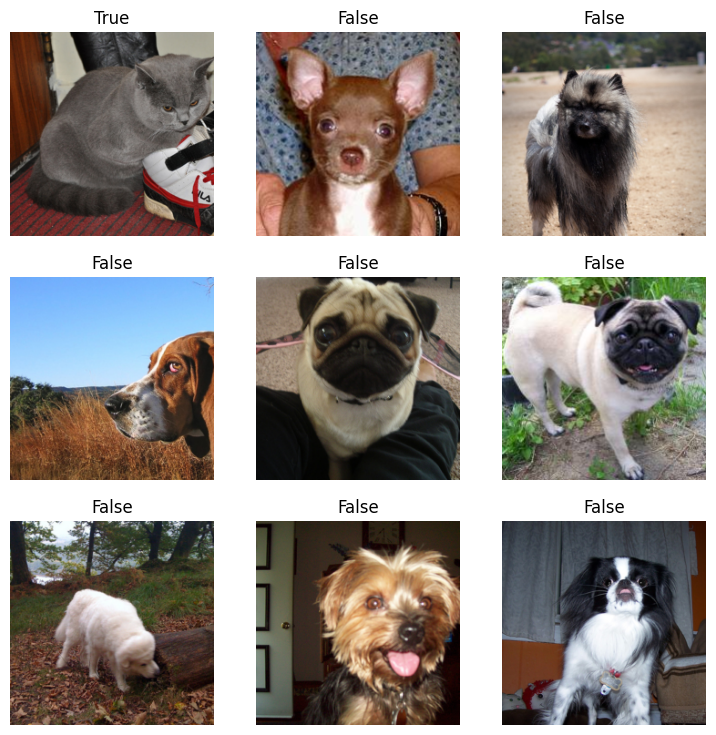

In [3]:
from fastai.vision.all import *

# download and decompress the data set.
# The result is a local path where the decompressed folder is located.
path = untar_data(URLs.PETS)

# The dataset contains a folder of images and other of annotations.
image_paths = get_image_files(path/"images")

# Create the dataloaders
dls = ImageDataLoaders.from_name_func(
    path, # Set the same directory for the dataset and the learner,
    image_paths, # pass the image paths
    lambda file_name: file_name[0].isupper(), # The file name for the cats start with uppercase
    item_tfms=Resize(224) # Transform each item by resizing to 224x224
);

dls.show_batch()

## Create learner & Fine tune

The learner puts together the dataloaders and the model that we want to fine tune.

In [4]:
learner = vision_learner(dls, resnet34, metrics=error_rate)
learner.fine_tune(1) # Train with one epoch

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 205MB/s] 


epoch,train_loss,valid_loss,error_rate,time
0,0.133351,0.012233,0.004736,14:01


epoch,train_loss,valid_loss,error_rate,time
0,0.050685,0.022146,0.006089,17:28


## Making predictions

In [14]:
# with dog image
sample_image_path = image_paths[101]
dog_image = PILImage.create(sample_image_path)
is_cat,_,probs = learner.predict(dog_image)
print("Is cat? ", is_cat)
print(f"Probability it's a cat: {probs[1].item():.6f}")

Is cat?  False
Probability it's a cat: 0.000000


In [20]:
sample_image_path = image_paths[5001]
cat_image = PILImage.create(sample_image_path)
is_cat,_,probs = learner.predict(cat_image)
print("Is cat? ", is_cat)
print(f"Probability it's a cat: {probs[1].item():.6f}")

Is cat?  True
Probability it's a cat: 1.000000
